# Battery state-of-charge estimation

**Goal:** estimate how much charge a battery has left using its temperature,
voltage and current.

SOC (state of charge) is a number between **0 and 1**: 0 means empty, 1 means full.
We predict a number, not a category, so this is a **regression** problem.

In this project we will:
1. Load, explore and clean four simulated battery recordings.
2. Split each recording into training, validation and test data.
3. Compare linear regression, polynomial regression, decision tree, random forest and SVR.
4. Choose a model using validation data, then evaluate it on test data.
5. Explain the results and the limits of this experiment.

## 0. Setup

We use **pandas** for tables, **NumPy** for numeric operations, **Matplotlib** for
plots, **SciPy** to read MATLAB files, and **scikit-learn** for machine learning.
At the end, **joblib** saves the trained model. `pathlib` is part of Python and handles paths.

Install `requirements.txt`, select that Python kernel, then **Restart Kernel and Run All Cells**.
Run from `final_project` or the repository root. No extra plotting or tuning library is needed.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
RANDOM_STATE = 42      # Same samples and tree models each time.
MAX_TRAIN_SAMPLES = 20_000   # Use None to train on all available training rows.
GAP_SAMPLES = 60       # Leave a small gap between neighbouring data partitions.
features = ['Temp', 'Voltage', 'Current']
numeric_columns = features + ['SOC']

project_dir = Path.cwd()
if not (project_dir / 'dataset').is_dir():
    project_dir = project_dir / 'final_project'
data_dir = project_dir / 'dataset'
assert data_dir.is_dir(), 'Run from final_project or the repository root.'

# Keep this notebook's outputs separate from the previous version's outputs.
output_dir = project_dir / 'outputs' / 'simple_notebook'
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Load and inspect the data

Each MATLAB file contains `X` (the three inputs) and `Y` (SOC).
The input order is **temperature (°C), voltage (V), current (A)**.
The small function below turns one file into a pandas table.

We keep the filename and original sample position so we can split and plot each
recording in order. These extra columns are **not model inputs**. Sample position
is not a measured timestamp.

In [3]:
def matdata_to_pd(filename, ambient_temperature):
    """Read one battery recording and keep its original row order."""
    data = loadmat(data_dir / filename)
    X = data['X']
    y = data['Y'].reshape(-1)   # Convert the SOC array into one column.
    if X.shape[0] == 3 and X.shape[1] != 3:
        X = X.T               # Some MATLAB arrays store samples as columns.
    assert X.shape == (len(y), 3), 'The inputs and SOC must have matching rows.'

    frame = pd.DataFrame(X.astype(float), columns=features)
    frame['SOC'] = y.astype(float)
    frame['source_file'] = filename
    frame['nominal_ambient_temp_C'] = ambient_temperature
    frame['sample_index'] = np.arange(len(frame))
    return frame

In [4]:
df_n10 = matdata_to_pd('BSOC_n10_degrees.mat', -10)
df_0 = matdata_to_pd('BSOC_0_degrees.mat', 0)
df_10 = matdata_to_pd('BSOC_10_degrees.mat', 10)
df_25 = matdata_to_pd('BSOC_25_degrees.mat', 25)

raw_df = pd.concat([df_n10, df_0, df_10, df_25], ignore_index=True)
print('Total rows:', len(raw_df))
raw_df.head()

Total rows: 144004


,Temp,Voltage,Current,SOC,source_file,nominal_ambient_temp_C,sample_index
0,25.000000,3.812794,14.974901,0.500000,BSOC_n10_degrees.mat,-10,0
1,24.841275,3.825451,14.986829,0.500154,BSOC_n10_degrees.mat,-10,1
2,24.683354,3.814582,14.975253,0.500309,BSOC_n10_degrees.mat,-10,2
3,24.526241,3.907865,15.067853,0.500463,BSOC_n10_degrees.mat,-10,3
4,24.369937,3.815818,14.975143,0.500617,BSOC_n10_degrees.mat,-10,4


In [5]:
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 144004 entries, 0 to 144003
Data columns (total 7 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Temp                    144004 non-null  float64
 1   Voltage                 144004 non-null  float64
 2   Current                 144004 non-null  float64
 3   SOC                     144004 non-null  float64
 4   source_file             144004 non-null  str    
 5   nominal_ambient_temp_C  144004 non-null  int64  
 6   sample_index            144004 non-null  int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 7.7 MB


In [6]:
raw_df[numeric_columns].describe().round(3)

,Temp,Voltage,Current,SOC
count,144004.000,144004.000,144004.000,144004.000
mean,10.329,3.990,1.140,0.779
std,14.395,0.210,13.447,0.191
min,-10.000,2.894,-55.029,0.214
25%,0.000,3.957,0.028,0.665
50%,10.001,4.079,0.691,0.888
75%,25.000,4.110,9.098,0.918
max,61.312,4.217,15.117,0.924


In [7]:
raw_df.groupby('source_file')[numeric_columns].agg(['min', 'max']).round(3)

Temp         Voltage        Current            SOC  \
                       min     max     min    max     min     max    min   
source_file                                                                
BSOC_0_degrees.mat    10.0  46.193   3.022  4.217 -54.223  15.115  0.231   
BSOC_10_degrees.mat    0.0  37.399   2.996  4.217 -54.223  15.115  0.233   
BSOC_25_degrees.mat   25.0  61.312   3.037  4.217 -55.029  15.117  0.214   
BSOC_n10_degrees.mat -10.0  29.715   2.894  4.217 -54.223  15.115  0.233   

                             
                        max  
source_file                  
BSOC_0_degrees.mat    0.922  
BSOC_10_degrees.mat   0.924  
BSOC_25_degrees.mat   0.918  
BSOC_n10_degrees.mat  0.924

**Important data warning:** the supplied `0_degrees` file has a measured minimum
temperature near 10°C, while the `10_degrees` file approaches 0°C. The filenames
may not match the simulation settings. We do not rename or silently swap them.
`nominal_ambient_temp_C` means **the label from the filename**, not a verified ambient
measurement. Our models use the measured `Temp` column instead.

## 2. Explore the data

### 2a. Missing values and repeated readings

`NaN` means missing; infinity is also not a usable measurement.
`nunique` counts distinct values and helps us spot constant columns.

,missing,infinite,unique_values
Temp,0,0,140554
Voltage,0,0,89837
Current,0,0,95468
SOC,0,0,115444


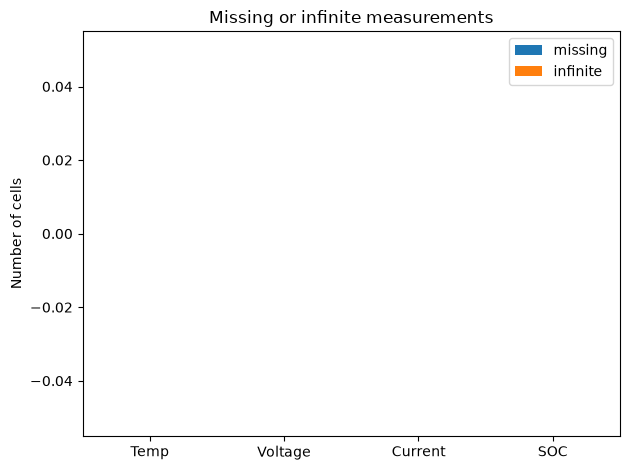

In [8]:
quality = pd.DataFrame({
    'missing': raw_df[numeric_columns].isna().sum(),
    'infinite': np.isinf(raw_df[numeric_columns]).sum(),
    'unique_values': raw_df[numeric_columns].nunique(),
})
display(quality)
quality[['missing', 'infinite']].plot.bar(title='Missing or infinite measurements', rot=0)
plt.ylabel('Number of cells')
plt.tight_layout()
plt.show()

In [9]:
print('Repeated measurement rows:', raw_df.duplicated(numeric_columns).sum())
identity_columns = ['source_file', 'sample_index']
assert not raw_df.duplicated(identity_columns).any(), 'Check duplicated sample identities.'

# Could the same three inputs have different SOC values?
soc_ranges = raw_df.groupby(features)['SOC'].agg(['min', 'max'])
conflicts = soc_ranges['max'] - soc_ranges['min'] > 1e-8
print('Input combinations with different SOC values:', conflicts.sum())

Repeated measurement rows: 3
Input combinations with different SOC values: 0


**Question:** should we remove every repeated measurement row?

**Answer:** no. A battery can return to the same operating state at a different
sample position. Those are real observations, not necessarily copied records.
We keep them. A repeated filename **and** sample index would need investigation;
the assertion checks that this has not happened.

### 2b. Distributions and unusual values

Histograms show common values. Box plots help identify unusual values, but an
outlier is not automatically a sensor error. Charging and discharging can produce
very different current values. Negative current and negative temperature can be valid.

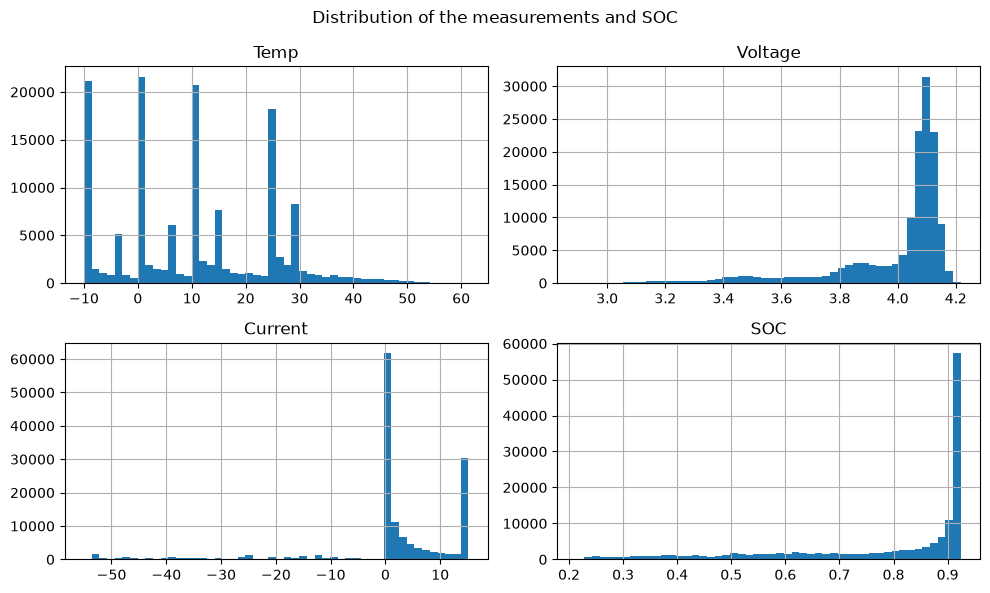

In [10]:
plot_values = raw_df[numeric_columns].replace([np.inf, -np.inf], np.nan)
plot_values.hist(bins=50, figsize=(10, 6))
plt.suptitle('Distribution of the measurements and SOC')
plt.tight_layout()
plt.show()

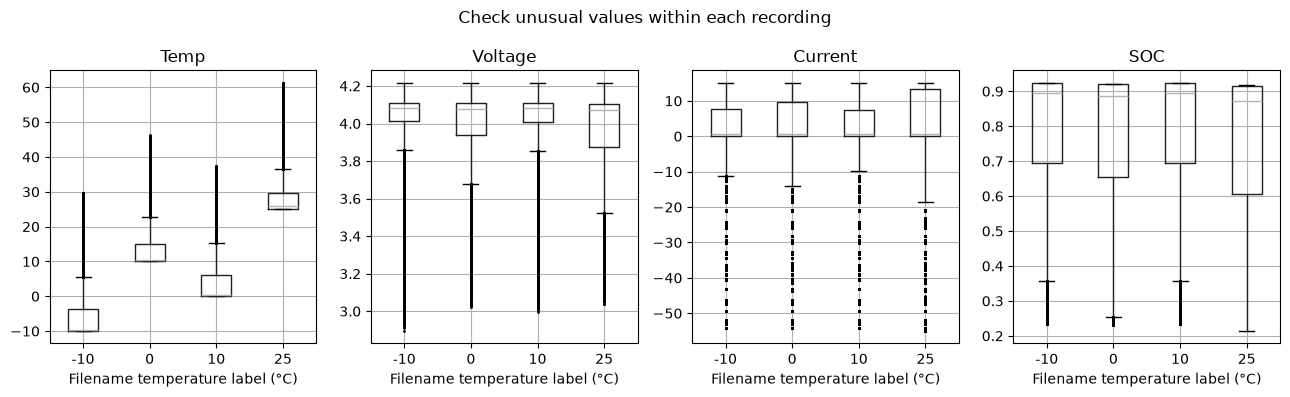

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, column in zip(axes, numeric_columns):
    raw_df.boxplot(column=column, by='nominal_ambient_temp_C', ax=ax,
                   flierprops={'markersize': 1})
    ax.set_title(column)
    ax.set_xlabel('Filename temperature label (°C)')
plt.suptitle('Check unusual values within each recording')
plt.tight_layout()
plt.show()

### 2c. Which SOC ranges are represented?

SOC is continuous, so these are **ranges, not classes**. We keep all ten ranges,
including empty ones. Many high-SOC rows can make an average error look good even
when lower-SOC estimates are weak. We will check errors by SOC range later.
We do not use classification oversampling methods such as SMOTE.

,rows,share_percent
SOC,,
0–10%,0,0.000000
10–20%,0,0.000000
20–30%,3565,2.475626
30–40%,6952,4.827644
40–50%,6817,4.733896
50–60%,10881,7.556040
60–70%,11999,8.332407
70–80%,11291,7.840754
80–90%,26549,18.436293


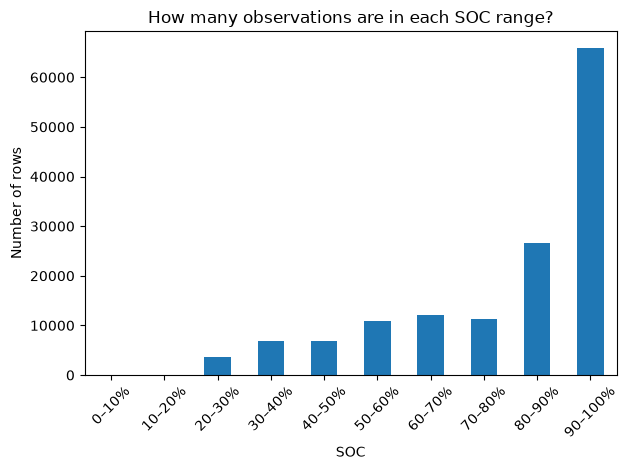

In [12]:
soc_edges = np.linspace(0, 1, 11)
soc_labels = [f'{i * 10}–{(i + 1) * 10}%' for i in range(10)]
raw_soc_bins = pd.cut(raw_df['SOC'], bins=soc_edges, labels=soc_labels, include_lowest=True)
soc_counts = raw_soc_bins.value_counts(sort=False).reindex(soc_labels, fill_value=0)
display(pd.DataFrame({'rows': soc_counts, 'share_percent': 100 * soc_counts / len(raw_df)}))

soc_counts.plot.bar(title='How many observations are in each SOC range?', rot=45)
plt.ylabel('Number of rows')
plt.tight_layout()
plt.show()

### 2d. Look at the recording order

We plot every twentieth row to keep the charts readable. This changes only the
plots, not the data used for evaluation. Adjacent samples are very similar, so
randomly mixing them into training and test sets could give misleading results.

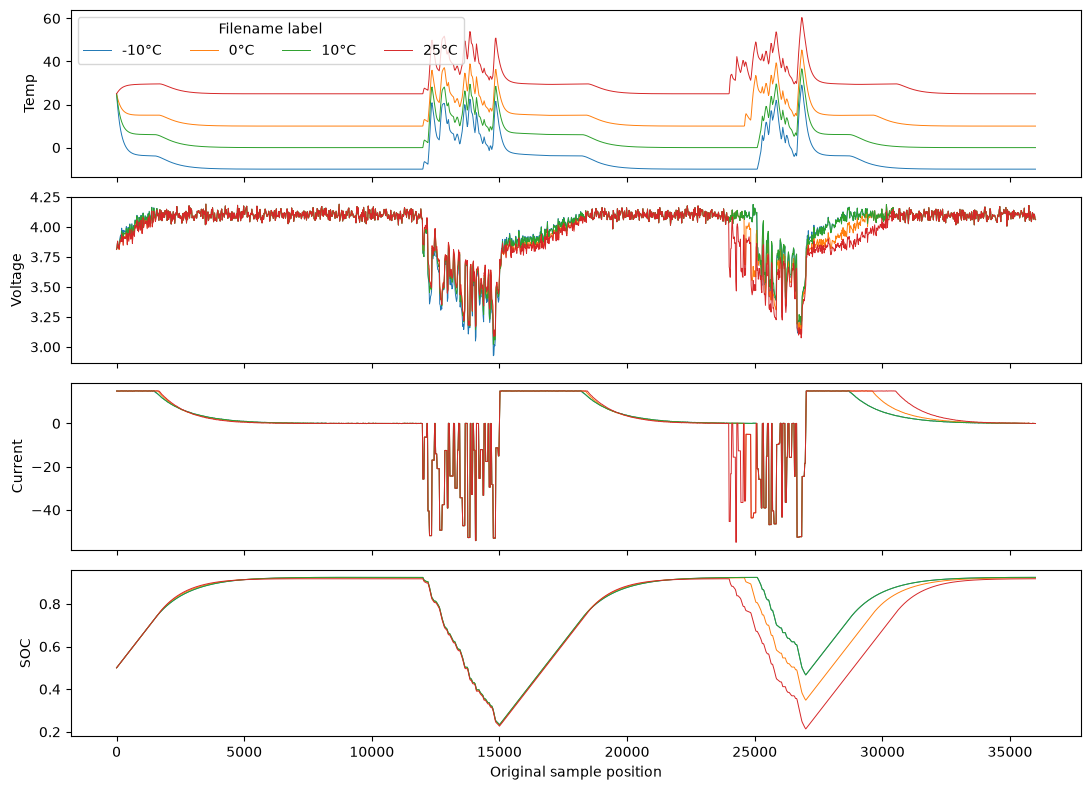

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ambient, group in raw_df.groupby('nominal_ambient_temp_C'):
    preview = group.iloc[::20]
    for ax, column in zip(axes, numeric_columns):
        ax.plot(preview['sample_index'], preview[column], label=f'{ambient}°C', linewidth=0.7)
        ax.set_ylabel(column)
axes[0].legend(title='Filename label', ncol=4)
axes[-1].set_xlabel('Original sample position')
plt.tight_layout()
plt.show()

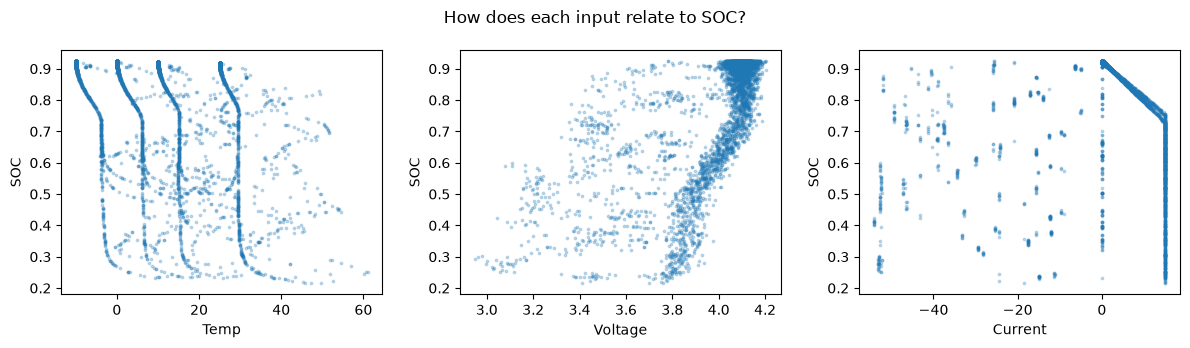

In [14]:
sample = raw_df.sample(n=min(5000, len(raw_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, column in zip(axes, features):
    ax.scatter(sample[column], sample['SOC'], s=3, alpha=0.25)
    ax.set_xlabel(column)
    ax.set_ylabel('SOC')
plt.suptitle('How does each input relate to SOC?')
plt.tight_layout()
plt.show()

## 3. Clean the data

We remove rows with missing/infinite values or clearly impossible measurements:
SOC outside [0, 1], voltage at or below zero, or temperature below absolute zero.
We do **not** invent missing SOC labels, remove plausible extremes, or guess
upper sensor limits without a battery specification. Large amounts of missing
data would require a different strategy.

`raw_df` stays unchanged. Rejected rows and their reasons are kept separately.

In [15]:
reasons = pd.DataFrame(index=raw_df.index)
reasons['nonfinite'] = ~np.isfinite(raw_df[numeric_columns]).all(axis=1)
reasons['physical_invalid'] = (
    ~raw_df['SOC'].between(0, 1)
    | (raw_df['Voltage'] <= 0)
    | (raw_df['Temp'] < -273.15)
)
bad_row = reasons.any(axis=1)
rejected_df = raw_df.loc[bad_row].join(reasons)
clean_df = raw_df.loc[~bad_row].copy()
clean_df = clean_df.sort_values(identity_columns).reset_index(drop=True)
clean_df['soc_bin'] = pd.cut(clean_df['SOC'], bins=soc_edges,
                            labels=soc_labels, include_lowest=True)

print('Rows before cleaning:', len(raw_df))
print('Rows removed:', len(rejected_df))
print('Rows kept:', len(clean_df))
assert len(clean_df) > 0
assert np.isfinite(clean_df[numeric_columns]).all().all()
assert clean_df['SOC'].between(0, 1).all()

Rows before cleaning: 144004
Rows removed: 0
Rows kept: 144004


For the supplied files, no rows need removing. **Cleaning does not have to delete
data to be useful:** checking and explaining why we keep it is also a valid decision.

## 4. Training, validation and test sets

For **each recording**, use the first 60% for training, the next 20% for validation,
and the final 20% for testing. `shuffle=False` preserves the recording order.
We also exclude the first 60 sample positions of validation and test as boundary gaps.

- **Training:** learn model parameters.
- **Validation:** compare settings and choose a model.
- **Test:** evaluate the chosen model only after the choice is fixed.

The gap reduces immediate neighbour overlap; it does not make these repeated
simulations independent. This tests later sections of the same recordings,
not unseen batteries or unseen temperatures.

In [16]:
train_parts, val_parts, test_parts = [], [], []
for filename, group in clean_df.groupby('source_file', sort=False):
    train_val, test = train_test_split(group, test_size=0.20, shuffle=False)
    train, val = train_test_split(train_val, test_size=0.25, shuffle=False)

    # Use original sample positions, even if cleaning removed some rows.
    val = val[val['sample_index'] >= val['sample_index'].min() + GAP_SAMPLES]
    test = test[test['sample_index'] >= test['sample_index'].min() + GAP_SAMPLES]
    assert len(train) > 0 and len(val) > 0 and len(test) > 0
    assert train['sample_index'].max() + GAP_SAMPLES < val['sample_index'].min()
    assert val['sample_index'].max() + GAP_SAMPLES < test['sample_index'].min()

    train_parts.append(train)
    val_parts.append(val)
    test_parts.append(test)

train_df = pd.concat(train_parts).sort_index()
val_df = pd.concat(val_parts).sort_index()
test_df = pd.concat(test_parts).sort_index()

In [17]:
# Rows excluded by the boundary gaps keep the label "gap".
clean_df['split'] = 'gap'
clean_df.loc[train_df.index, 'split'] = 'train'
clean_df.loc[val_df.index, 'split'] = 'validation'
clean_df.loc[test_df.index, 'split'] = 'test'

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)
pd.crosstab(clean_df['nominal_ambient_temp_C'], clean_df['split'])

split,gap,test,train,validation
nominal_ambient_temp_C,,,,
-10,120,7141,21600,7140
0,120,7141,21600,7140
10,120,7141,21600,7140
25,120,7141,21600,7140


Different sample identities can still have identical measurements. We count exact
measurement overlap separately rather than assuming that disjoint row numbers are enough.

In [18]:
overlap_rows = []
for left_name, left, right_name, right in [
    ('train', train_df, 'validation', val_df),
    ('train', train_df, 'test', test_df),
    ('validation', val_df, 'test', test_df),
]:
    left_values = left[numeric_columns].drop_duplicates()
    right_values = right[numeric_columns].drop_duplicates()
    shared = left_values.merge(right_values, on=numeric_columns)
    overlap_rows.append({'partitions': left_name + ' / ' + right_name,
                         'shared_measurements': len(shared)})
display(pd.DataFrame(overlap_rows))

,partitions,shared_measurements
0,train / validation,0
1,train / test,0
2,validation / test,0


### 4a. A common training sample

Kernel SVR can be slow on a large dataset. To keep the comparison practical, all
models learn from the **same 20,000 training rows** by default.

We sample within combinations of filename temperature label and SOC range.
`stratify` preserves their proportions; it does not balance ranges or create rows.
This random sampling happens **inside training only**, after the ordered split.
Validation and test scores still use every row in those partitions.

In [19]:
def training_subset(frame):
    """Take a repeatable sample while preserving temperature/SOC proportions."""
    if MAX_TRAIN_SAMPLES is None or len(frame) <= MAX_TRAIN_SAMPLES:
        return frame.copy()

    groups = frame['nominal_ambient_temp_C'].astype(str) + '|' + frame['soc_bin'].astype(str)
    selected, unused = train_test_split(
        frame, train_size=MAX_TRAIN_SAMPLES, stratify=groups,
        random_state=RANDOM_STATE)
    return selected.sort_index()

fit_df = training_subset(train_df)
X_fit = fit_df[features]
y_fit = fit_df['SOC']
X_val = val_df[features]
y_val = val_df['SOC']

print('Training rows used by each model:', len(fit_df), 'out of', len(train_df))
print('Validation rows:', len(val_df), ' Test rows:', len(test_df))

Training rows used by each model: 20000 out of 86400
Validation rows: 28560  Test rows: 28564


In [20]:
pd.crosstab(fit_df['nominal_ambient_temp_C'], fit_df['soc_bin'], dropna=False)

soc_bin,0–10%,10–20%,20–30%,30–40%,40–50%,50–60%,60–70%,70–80%,80–90%,90–100%
nominal_ambient_temp_C,,,,,,,,,,
-10,0,0,155,305,229,399,414,413,1017,2068
0,0,0,159,305,229,399,414,391,979,2124
10,0,0,155,305,229,399,414,412,1017,2070
25,0,0,168,304,252,378,413,385,945,2154


### 4b. Compare SOC coverage after splitting

Later parts of a recording may cover different SOC ranges. This helps explain
why training, validation and test errors can differ even without overfitting.
The correlation table below uses training rows only; correlation is not causation.

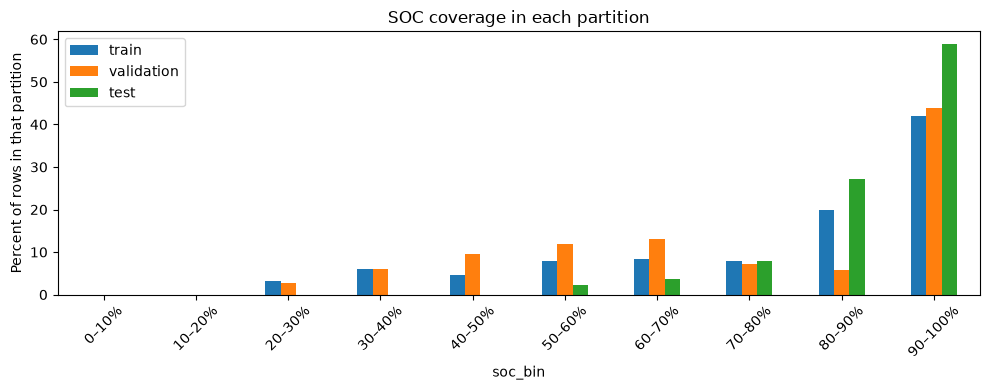

,Temp,Voltage,Current,SOC
Temp,1.000,-0.377,-0.201,-0.305
Voltage,-0.377,1.000,0.648,0.709
Current,-0.201,0.648,1.000,-0.041
SOC,-0.305,0.709,-0.041,1.000


In [21]:
coverage = pd.DataFrame({
    'train': train_df['soc_bin'].value_counts(sort=False),
    'validation': val_df['soc_bin'].value_counts(sort=False),
    'test': test_df['soc_bin'].value_counts(sort=False),
}).reindex(soc_labels).fillna(0)
coverage_percent = 100 * coverage / coverage.sum()
coverage_percent.plot.bar(figsize=(10, 4), rot=45, title='SOC coverage in each partition')
plt.ylabel('Percent of rows in that partition')
plt.tight_layout()
plt.show()
display(train_df[numeric_columns].corr().round(3))

## 5. Scale the inputs — training data only

Temperature, voltage and current have different units. `MinMaxScaler` uses
`(value - training minimum) / (training maximum - training minimum)` to put each
training input on a 0–1 scale. This is especially important for SVR.
SOC already uses a meaningful 0–1 scale, so we leave it unchanged.

**Golden rule:** learn scaling limits from training data only. Validation/test
values can fall outside those limits and become less than 0 or greater than 1.
That is allowed: we do not clip them or learn their ranges in advance.

In [22]:
preview_scaler = MinMaxScaler()
scaled_fit = pd.DataFrame(preview_scaler.fit_transform(X_fit), columns=features)
scaled_val = pd.DataFrame(preview_scaler.transform(X_val), columns=features)

assert X_fit.nunique().gt(1).all(), 'Review constant input columns.'
display(scaled_fit.head())
display(pd.DataFrame({
    'training_min': scaled_fit.min(),
    'training_max': scaled_fit.max(),
    'validation_min': scaled_val.min(),
    'validation_max': scaled_val.max(),
}))

,Temp,Voltage,Current
0,0.540585,0.696604,0.998157
1,0.534508,0.715954,0.998438
2,0.529491,0.717893,0.998421
3,0.528672,0.700476,0.998093
4,0.523862,0.704623,0.998126


,training_min,training_max,validation_min,validation_max
Temp,0.0,1.0,0.000002,1.103247
Voltage,0.0,1.0,0.085899,0.986570
Current,0.0,1.0,-0.011668,0.999757


### Why use a pipeline?

`make_pipeline(MinMaxScaler(), model)` joins scaling and prediction into one object.
When we call `fit`, it learns the scaler and then the model from the same training
rows. When we call `predict`, it applies that learned scaler automatically.

The preview above is only to show what scaling does. Below, we always pass
**raw inputs** to a pipeline — never scale them twice. Trees do not need scaling,
but keeping it for all five models preserves the original comparison.

## 6. How will we measure performance?

- **MAE:** the average absolute error. Easy to interpret.
- **RMSE:** also an error measure, but gives more weight to large mistakes.
- **R²:** 1 is perfect; 0 matches predicting the evaluated set's mean; it can be negative.
  It is **not classification accuracy**.

We multiply MAE and RMSE by 100 to report **SOC percentage points (pp)**.
For example, predicting 0.78 instead of 0.80 is an error of **2 pp**.
We will choose the model with the lowest **validation RMSE**.

In [23]:
def regression_metrics(actual, predicted):
    """Return errors in SOC percentage points, plus R²."""
    return {
        'MAE_pp': 100 * mean_absolute_error(actual, predicted),
        'RMSE_pp': 100 * np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted),
    }

### 6a. A baseline: always predict the training mean

A useful model should improve on this simple guess.

In [24]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_fit, y_fit)
baseline_validation = regression_metrics(y_val, baseline.predict(X_val))
pd.Series(baseline_validation, name='Mean baseline: validation')

MAE_pp     18.361201
RMSE_pp    21.170080
R2         -0.032185
Name: Mean baseline: validation, dtype: float64

## 7. Train and compare five regression models

Each model has its own short training cell. We try the same small set of settings
as the original notebook. This is a **validation holdout comparison**, not cross-validation.

The helper below only records scores and remembers the best fitted model in each
family. The actual `fit` calls stay visible in the cells that follow.

In [25]:
search_rows = []
best_models = {}
best_errors = {}

def record_result(name, settings, model):
    """Score one fitted model, and keep it if it improves validation RMSE."""
    train_scores = regression_metrics(y_fit, model.predict(X_fit))
    val_scores = regression_metrics(y_val, model.predict(X_val))
    search_rows.append({
        'model': name, 'settings': settings,
        'train_RMSE_pp': train_scores['RMSE_pp'],
        'val_MAE_pp': val_scores['MAE_pp'],
        'val_RMSE_pp': val_scores['RMSE_pp'],
        'val_R2': val_scores['R2'],
    })
    if name not in best_errors or val_scores['RMSE_pp'] < best_errors[name]:
        best_models[name] = model
        best_errors[name] = val_scores['RMSE_pp']
    print(name, settings, '— validation RMSE:', round(val_scores['RMSE_pp'], 3), 'pp')

### 7a. Linear regression

Learns a weighted sum of temperature, voltage and current, plus an intercept.
It is our simplest learned model, but may miss curved relationships.

In [26]:
linear_model = make_pipeline(MinMaxScaler(), LinearRegression())
linear_model.fit(X_fit, y_fit)
record_result('Linear regression', 'default', linear_model)

Linear regression default — validation RMSE: 5.583 pp


### 7b. Polynomial regression

Adds powers and combinations such as voltage² and voltage × current before
linear regression. This allows curves without introducing a different estimator.
We compare degrees 2 and 3. Higher degrees can overfit.
`include_bias=False` avoids adding a constant column: linear regression already has an intercept.

In [27]:
for degree in [2, 3]:
    polynomial_model = make_pipeline(
        MinMaxScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression())
    polynomial_model.fit(X_fit, y_fit)
    record_result('Polynomial regression', f'degree={degree}', polynomial_model)

Polynomial regression degree=2 — validation RMSE: 4.52 pp
Polynomial regression degree=3 — validation RMSE: 4.254 pp


### 7c. Decision tree

Learns a series of questions, such as "is voltage below this value?"
`max_depth` limits the number of question levels; `min_samples_leaf` requires
enough training examples in each final group. Both help control overfitting.

In [28]:
for depth in [8, 16]:
    for leaf_size in [10, 30]:
        tree_model = make_pipeline(
            MinMaxScaler(),
            DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf_size,
                                  random_state=RANDOM_STATE))
        tree_model.fit(X_fit, y_fit)
        settings = f'depth={depth}, leaf={leaf_size}'
        record_result('Decision tree', settings, tree_model)

Decision tree depth=8, leaf=10 — validation RMSE: 6.594 pp


Decision tree depth=8, leaf=30 — validation RMSE: 6.029 pp


Decision tree depth=16, leaf=10 — validation RMSE: 5.88 pp
Decision tree depth=16, leaf=30 — validation RMSE: 5.549 pp


### 7d. Random forest

Averages predictions from many trees trained with randomness, usually making
predictions more stable than a single tree. We use 100 trees and compare two
depth limits and two minimum leaf sizes. `None` allows unlimited depth.
`n_jobs=-1` uses the available CPU cores to speed up training.

In [29]:
for depth in [16, None]:
    for leaf_size in [3, 10]:
        forest_model = make_pipeline(
            MinMaxScaler(),
            RandomForestRegressor(n_estimators=100, max_depth=depth,
                                  min_samples_leaf=leaf_size,
                                  random_state=RANDOM_STATE, n_jobs=-1))
        forest_model.fit(X_fit, y_fit)
        settings = f'depth={depth}, leaf={leaf_size}'
        record_result('Random forest', settings, forest_model)

Random forest depth=16, leaf=3 — validation RMSE: 5.54 pp


Random forest depth=16, leaf=10 — validation RMSE: 5.159 pp


Random forest depth=None, leaf=3 — validation RMSE: 5.52 pp


Random forest depth=None, leaf=10 — validation RMSE: 5.159 pp


### 7e. Support vector regression (SVR)

The regression version of a support vector machine. The **RBF kernel** allows a
curved relationship between inputs and SOC.

- `C` controls the penalty for training errors; larger values fit more strictly.
- `epsilon=0.005` allows a 0.5 pp margin before errors are penalized.
- `gamma='scale'` lets scikit-learn calculate the kernel's influence range from the scaled training inputs.
- `cache_size=512` reserves up to 512 MB for kernel calculations; it affects speed, not the model choice.

This is the slowest training section. We compare `C=10` and `C=100`.

In [30]:
for C in [10, 100]:
    svr_model = make_pipeline(
        MinMaxScaler(),
        SVR(kernel='rbf', C=C, epsilon=0.005, gamma='scale', cache_size=512))
    svr_model.fit(X_fit, y_fit)
    record_result('SVM (SVR)', f'C={C}', svr_model)

SVM (SVR) C=10 — validation RMSE: 4.235 pp


SVM (SVR) C=100 — validation RMSE: 4.594 pp


## 8. Which model performed best on validation data?

Keep the lowest-validation-RMSE setting from each family, then rank the five
families. Test scores do not enter this decision.

In [31]:
search_results = pd.DataFrame(search_rows)
comparison = search_results.sort_values('val_RMSE_pp', kind='stable')
comparison = comparison.drop_duplicates('model').reset_index(drop=True)
comparison['RMSE_gap_pp'] = comparison['val_RMSE_pp'] - comparison['train_RMSE_pp']

winner_name = comparison.loc[0, 'model']
selected_model = best_models[winner_name]
display(comparison.round(4))
print('Chosen using validation RMSE only:', winner_name)

,model,settings,train_RMSE_pp,val_MAE_pp,val_RMSE_pp,val_R2,RMSE_gap_pp
0,SVM (SVR),C=10,3.0738,2.5414,4.2353,0.9587,1.1615
1,Polynomial regression,degree=3,3.5471,2.7207,4.2536,0.9583,0.7066
2,Random forest,"depth=16, leaf=10",1.0294,2.4914,5.1586,0.9387,4.1293
3,Decision tree,"depth=16, leaf=30",1.8726,2.9968,5.5492,0.9291,3.6766
4,Linear regression,default,5.1481,4.2627,5.5829,0.9282,0.4349


Chosen using validation RMSE only: SVM (SVR)


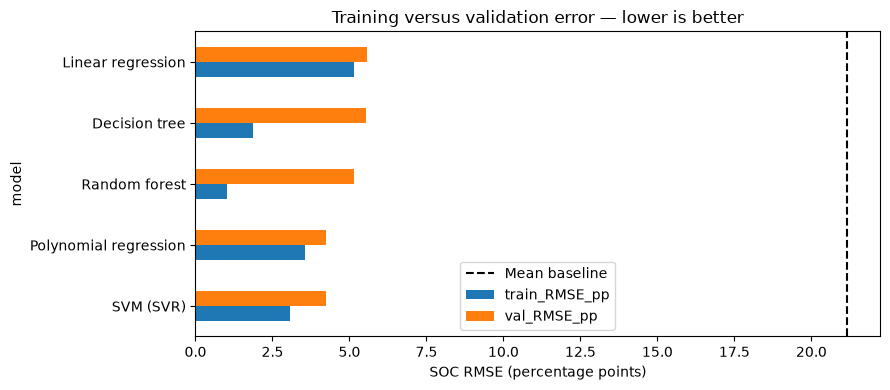

In [32]:
comparison.set_index('model')[['train_RMSE_pp', 'val_RMSE_pp']].plot.barh(figsize=(9, 4))
plt.axvline(baseline_validation['RMSE_pp'], color='black', linestyle='--', label='Mean baseline')
plt.xlabel('SOC RMSE (percentage points)')
plt.title('Training versus validation error — lower is better')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / 'model_comparison.png', dpi=130)
plt.show()

**Question:** does the lowest training error mean the best model?

**Answer:** no. A model can memorize training patterns but perform worse on later
data. Compare validation error and the training–validation gap. A large gap can
suggest overfitting, but different operating conditions can also contribute.
Small differences between the top models are not proof that one is always best.

### 8a. Validation errors by filename temperature label

An overall average can hide a weak recording. These are still validation
comparisons; we are not repeatedly choosing models using the test set.

In [33]:
validation_rows = []
for name, model in best_models.items():
    for ambient, group in val_df.groupby('nominal_ambient_temp_C'):
        prediction = model.predict(group[features])
        scores = regression_metrics(group['SOC'], prediction)
        validation_rows.append({'model': name, 'nominal_ambient_temp_C': ambient,
                                'n': len(group), 'RMSE_pp': scores['RMSE_pp']})
validation_groups = pd.DataFrame(validation_rows)
validation_groups.pivot(index='model', columns='nominal_ambient_temp_C', values='RMSE_pp').round(3)

nominal_ambient_temp_C,-10,0,10,25
model,,,,
Decision tree,5.389,4.649,5.024,6.876
Linear regression,6.014,4.786,4.973,6.393
Polynomial regression,3.978,3.953,3.522,5.340
Random forest,5.416,4.063,4.777,6.147
SVM (SVR),3.994,4.138,3.809,4.916


### 8b. Which inputs does the selected model rely on?

**Permutation importance** shuffles one input at a time and measures how much
prediction error increases. A larger increase means the input helped this model.
We use a validation sample and the model trained **before** the final refit.
Five repetitions show how much the result varies with the shuffle.
Correlated inputs can share importance; this does not prove physical cause and effect.

,feature,RMSE_increase_pp,std_pp
0,Temp,2.570,0.034
2,Current,26.589,0.496
1,Voltage,27.408,0.614


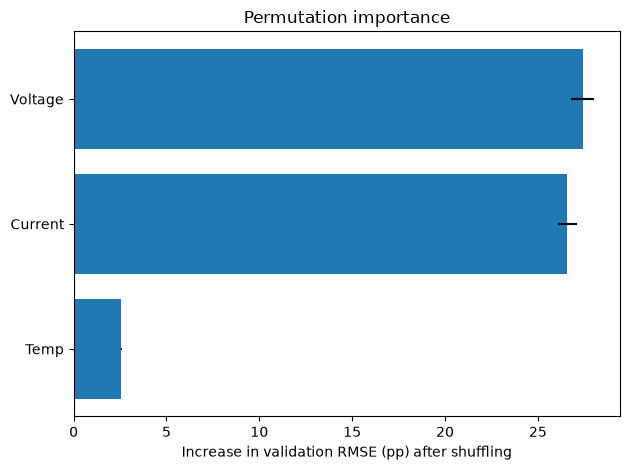

In [34]:
from sklearn.inspection import permutation_importance

interpret_df = val_df.sample(n=min(3000, len(val_df)), random_state=RANDOM_STATE)
importance = permutation_importance(
    selected_model, interpret_df[features], interpret_df['SOC'],
    scoring='neg_root_mean_squared_error', n_repeats=5, random_state=RANDOM_STATE)
importance_df = pd.DataFrame({
    'feature': features,
    'RMSE_increase_pp': 100 * importance.importances_mean,
    'std_pp': 100 * importance.importances_std,
}).sort_values('RMSE_increase_pp')
display(importance_df.round(3))
plt.barh(importance_df['feature'], importance_df['RMSE_increase_pp'], xerr=importance_df['std_pp'])
plt.xlabel('Increase in validation RMSE (pp) after shuffling')
plt.title('Permutation importance')
plt.tight_layout()
plt.show()

## 9. Refit the chosen model, then evaluate on test data

The family and settings are now fixed. Combine training and validation rows,
take the same type of budgeted sample, and fit a **fresh copy** of the chosen
pipeline. `clone` copies its settings, not its learned values, so the final
scaler and model learn again from the development sample.

Test rows and boundary-gap rows are not used for fitting. We compare the final
model with a baseline fitted on exactly the same development sample.

In [35]:
from sklearn.base import clone

development_df = pd.concat([train_df, val_df]).sort_index()
final_fit_df = training_subset(development_df)
final_model = clone(selected_model)
final_model.fit(final_fit_df[features], final_fit_df['SOC'])

X_test = test_df[features]
y_test = test_df['SOC']
test_prediction = final_model.predict(X_test)
test_metrics = regression_metrics(y_test, test_prediction)

final_baseline = DummyRegressor(strategy='mean')
final_baseline.fit(final_fit_df[features], final_fit_df['SOC'])
baseline_test = regression_metrics(y_test, final_baseline.predict(X_test))

test_results = pd.DataFrame([test_metrics, baseline_test], index=[winner_name, 'Mean baseline'])
display(test_results.round(4))
print('Final fitting rows:', len(final_fit_df), 'out of', len(development_df))
print('Test rows scored:', len(test_df))

,MAE_pp,RMSE_pp,R2
SVM (SVR),0.5622,1.2800,0.9751
Mean baseline,13.4664,14.2057,-2.0638


Final fitting rows: 20000 out of 114960
Test rows scored: 28564


In [36]:
assert np.isfinite(test_prediction).all()
print('Predictions outside [0, 1]:', ((test_prediction < 0) | (test_prediction > 1)).sum())
outside_fit_range = (y_test < y_fit.min()) | (y_test > y_fit.max())
print('Test SOC values outside the candidate training range:', outside_fit_range.sum())

test_detail = test_df.copy()
test_detail['predicted_SOC'] = test_prediction
test_detail['residual_pp'] = 100 * (test_detail['SOC'] - test_detail['predicted_SOC'])
test_detail['absolute_error_pp'] = test_detail['residual_pp'].abs()

Predictions outside [0, 1]: 0
Test SOC values outside the candidate training range: 1153


We report the raw predictions, without clipping them into [0, 1]. Clipping could
hide a model problem. The test result describes this particular later segment;
it is not a claim of accuracy on all batteries or across the full SOC range.

### 9a. Look at one prediction

In [37]:
i = 50
print('Inputs:')
print(X_test.iloc[i])
print('Actual SOC (%):', round(100 * y_test.iloc[i], 2))
print('Predicted SOC (%):', round(100 * test_prediction[i], 2))
print('Absolute error (pp):', round(100 * abs(y_test.iloc[i] - test_prediction[i]), 2))

Inputs:
Temp       15.031976
Voltage     4.034521
Current    15.030465
Name: 28910, dtype: float64
Actual SOC (%): 64.3
Predicted SOC (%): 68.66
Absolute error (pp): 4.36


### 9b. Predictions and residuals

The diagonal represents perfect predictions. A **residual** is actual SOC minus
predicted SOC: a positive value means we underestimated the charge.
Patterns in residuals can reveal errors that a single score hides.
The scatter plots use a sample for readability; the histogram and metrics use all test rows.

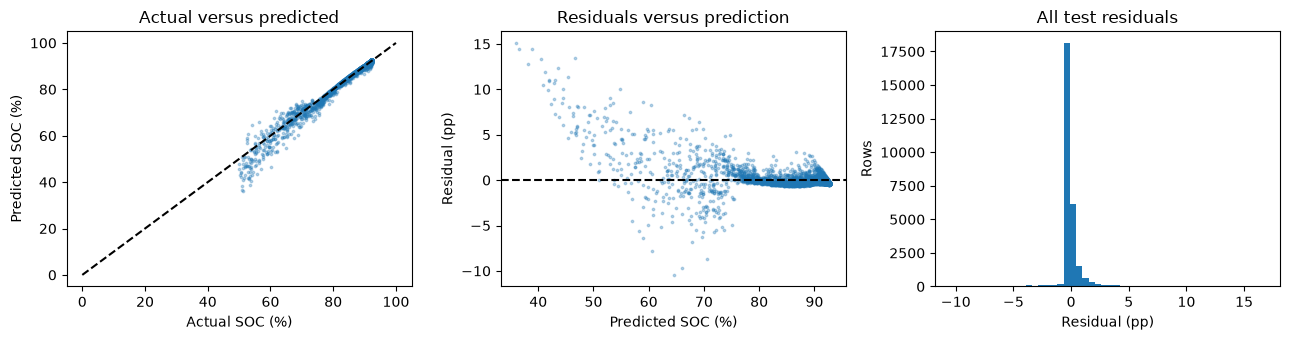

In [38]:
sample = test_detail.sample(n=min(5000, len(test_detail)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].scatter(100 * sample['SOC'], 100 * sample['predicted_SOC'], s=3, alpha=0.3)
axes[0].plot([0, 100], [0, 100], 'k--')
axes[0].set(xlabel='Actual SOC (%)', ylabel='Predicted SOC (%)', title='Actual versus predicted')
axes[1].scatter(100 * sample['predicted_SOC'], sample['residual_pp'], s=3, alpha=0.3)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted SOC (%)', ylabel='Residual (pp)', title='Residuals versus prediction')
axes[2].hist(test_detail['residual_pp'], bins=50)
axes[2].set(xlabel='Residual (pp)', ylabel='Rows', title='All test residuals')
plt.tight_layout()
plt.savefig(output_dir / 'test_diagnostics.png', dpi=130)
plt.show()

### 9c. Follow the predictions in recording order

These plots show every tenth test row. Close curves mean the estimates follow
the true SOC; separate curves reveal where they fail to do so.

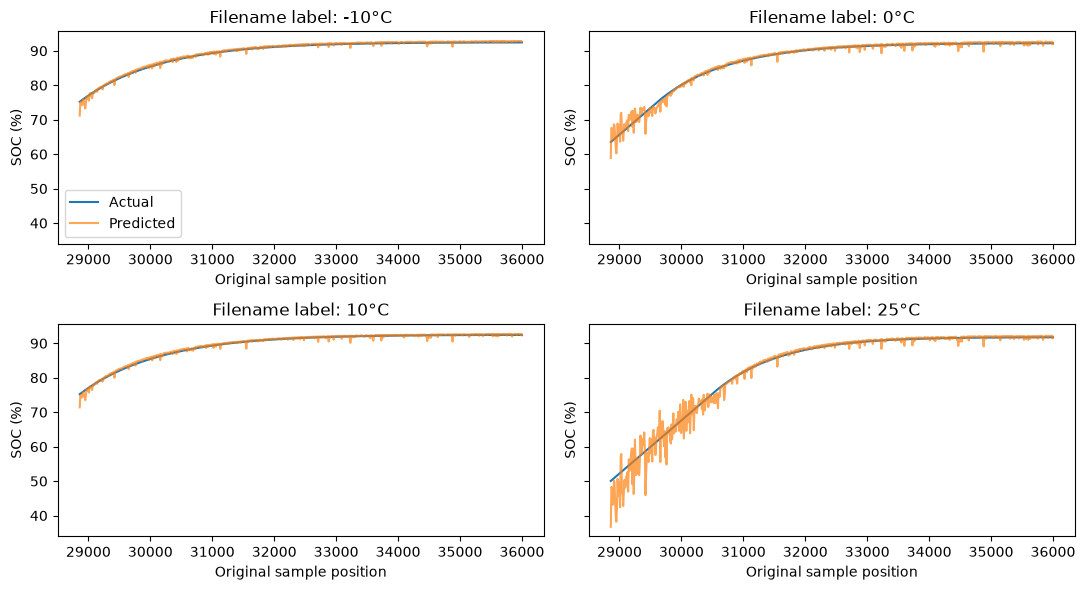

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharey=True)
for ax, (ambient, group) in zip(axes.flat, test_detail.groupby('nominal_ambient_temp_C')):
    preview = group.sort_values('sample_index').iloc[::10]
    ax.plot(preview['sample_index'], 100 * preview['SOC'], label='Actual')
    ax.plot(preview['sample_index'], 100 * preview['predicted_SOC'], label='Predicted', alpha=0.7)
    ax.set(title=f'Filename label: {ambient}°C', xlabel='Original sample position', ylabel='SOC (%)')
axes.flat[0].legend()
plt.tight_layout()
plt.savefig(output_dir / 'test_sequences.png', dpi=130)
plt.show()

### 9d. Errors by recording and SOC range

Include the number of rows: a score based on few examples gives weaker evidence.
Empty SOC ranges have **no measured error**, not zero error. `bias_pp` is the mean
residual; positive bias means underestimation. These are descriptive checks,
not an invitation to retune on test results.

In [40]:
temperature_rows = []
for ambient, group in test_detail.groupby('nominal_ambient_temp_C'):
    scores = regression_metrics(group['SOC'], group['predicted_SOC'])
    temperature_rows.append({
        'nominal_ambient_temp_C': ambient, 'n': len(group),
        'MAE_pp': scores['MAE_pp'], 'RMSE_pp': scores['RMSE_pp'], 'R2': scores['R2'],
        'bias_pp': group['residual_pp'].mean(),
    })
temperature_test = pd.DataFrame(temperature_rows)
display(temperature_test.round(4))

soc_test = test_detail.groupby('soc_bin', observed=False).agg(
    n=('SOC', 'size'), MAE_pp=('absolute_error_pp', 'mean'), bias_pp=('residual_pp', 'mean'))
display(soc_test.reindex(soc_labels).round(4))

,nominal_ambient_temp_C,n,MAE_pp,RMSE_pp,R2,bias_pp
0,-10,7141,0.3104,0.4148,0.9901,-0.1608
1,0,7141,0.5372,0.9872,0.9819,-0.0546
2,10,7141,0.2774,0.4064,0.9905,-0.0860
3,25,7141,1.1239,2.2894,0.9640,0.3237


,n,MAE_pp,bias_pp
soc_bin,,,
0–10%,0,NaN,NaN
10–20%,0,NaN,NaN
20–30%,0,NaN,NaN
30–40%,0,NaN,NaN
40–50%,0,NaN,NaN
50–60%,645,4.8916,3.4619
60–70%,1068,2.7489,-0.1170
70–80%,2229,1.1404,0.8033
80–90%,7790,0.3699,-0.1944


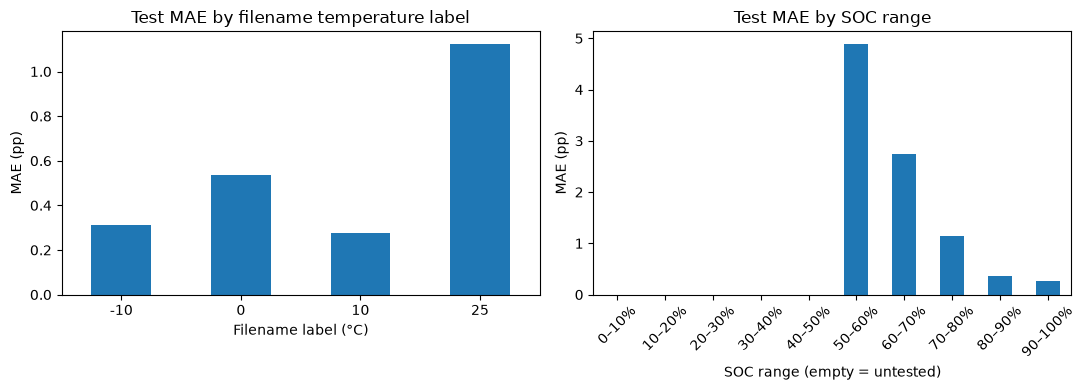

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
temperature_test.plot.bar(x='nominal_ambient_temp_C', y='MAE_pp', ax=axes[0], rot=0, legend=False)
axes[0].set(title='Test MAE by filename temperature label', xlabel='Filename label (°C)', ylabel='MAE (pp)')
soc_test['MAE_pp'].plot.bar(ax=axes[1], rot=45)
axes[1].set(title='Test MAE by SOC range', xlabel='SOC range (empty = untested)', ylabel='MAE (pp)')
plt.tight_layout()
plt.show()

## 10. Save the useful results

Save the cleaned data in original units, rejected rows, model comparison, test
predictions and fitted pipeline. The cleaned file includes split membership and
flags showing which rows were actually used for candidate and final fitting.
Figures above are saved for use in the presentation.

The saved pipeline accepts raw `Temp`, `Voltage`, `Current` columns in that order;
it already contains the final scaler. **Do not scale inputs again.**
Only load joblib files from trusted sources.

In [42]:
import joblib
import json

clean_export = clean_df.copy()
clean_export['candidate_fit'] = clean_export.index.isin(fit_df.index)
clean_export['final_fit'] = clean_export.index.isin(final_fit_df.index)
clean_export.to_csv(output_dir / 'clean_battery_soc.csv.gz', index=False)
rejected_df.to_csv(output_dir / 'rejected_rows.csv', index=False)
search_results.to_csv(output_dir / 'hyperparameter_search.csv', index=False)
comparison.to_csv(output_dir / 'validation_model_comparison.csv', index=False)
validation_groups.to_csv(output_dir / 'validation_temperature_metrics.csv', index=False)
importance_df.to_csv(output_dir / 'validation_permutation_importance.csv', index=False)
test_results.to_csv(output_dir / 'test_metrics.csv', index_label='model')
temperature_test.to_csv(output_dir / 'test_temperature_metrics.csv', index=False)
soc_test.to_csv(output_dir / 'test_soc_bin_metrics.csv')
test_detail.to_csv(output_dir / 'test_predictions.csv.gz', index=False)
joblib.dump(final_model, output_dir / 'best_soc_pipeline.joblib', compress=3)
print('Saved results to:', output_dir)

Saved results to: /mnt/d/repositories/machine_learning/final_project/outputs/simple_notebook


In [43]:
# Record settings so the experiment can be repeated.
run_settings = {
    'random_state': RANDOM_STATE,
    'max_train_samples': MAX_TRAIN_SAMPLES,
    'gap_samples': GAP_SAMPLES,
    'features': features,
    'selected_model': winner_name,
    'selected_settings': comparison.loc[0, 'settings'],
    'selection_metric': 'validation RMSE_pp',
    'candidate_fit_rows': len(fit_df),
    'final_fit_rows': len(final_fit_df),
    'test_metrics': test_metrics,
}
with open(output_dir / 'run_settings.json', 'w') as file:
    json.dump(run_settings, file, indent=2)

## 11. Summary and interpretation

These numbers are calculated from this run, not written in advance.

In [44]:
improvement = 100 * (1 - test_metrics['RMSE_pp'] / baseline_test['RMSE_pp'])
worst_group = temperature_test.loc[temperature_test['MAE_pp'].idxmax()]
print('Chosen model:', winner_name)
print('Chosen settings:', comparison.loc[0, 'settings'])
print('Validation RMSE before final refit:', round(comparison.loc[0, 'val_RMSE_pp'], 3), 'pp')
print('Final test MAE:', round(test_metrics['MAE_pp'], 3), 'pp')
print('Final test RMSE:', round(test_metrics['RMSE_pp'], 3), 'pp')
print('Final test R²:', round(test_metrics['R2'], 4))
print('Test RMSE reduction versus mean baseline:', round(improvement, 1), '%')
print('Highest test MAE was in filename temperature group:', worst_group['nominal_ambient_temp_C'], '°C')

Chosen model: SVM (SVR)
Chosen settings: C=10
Validation RMSE before final refit: 4.235 pp
Final test MAE: 0.562 pp
Final test RMSE: 1.28 pp
Final test R²: 0.9751
Test RMSE reduction versus mean baseline: 91.0 %
Highest test MAE was in filename temperature group: 25.0 °C


### What these results can — and cannot — tell us

- **Useful comparison:** all five families use the same candidate training rows,
  validation rows and selection metric. The test set is not used to choose settings.
- **Limited coverage:** these are four simulated recordings with a repeated operating
  schedule, not independent real batteries. Missing SOC ranges remain untested.
  A lower test error than validation error may reflect easier later operating conditions.
- **Uneven errors:** inspect recording/SOC-range results, not only the overall average.
  Filename-label problems also limit interpretation of temperature-group differences.
- **Safety:** SOC errors can affect range and charging decisions. This academic model
  is not validated for use in a battery-management or protection system.
- **Next experiments:** collect independent batteries, more SOC ranges and operating
  conditions; hold out entire recordings/batteries; try full training data and blocked
  validation. Past measurements might help, but never use future readings as inputs.
- **Data governance:** the supplied simulated inputs contain no personal data. Check
  MathWorks redistribution terms before publishing them; a documentation link is not a licence.

### Explain it in your own words before submission

1. Why did you choose SOC estimation, and why is it regression rather than classification?
2. Why keep repeated readings and plausible outliers?
3. Why split in recording order and learn scaling limits from training only?
4. What is the difference between MAE, RMSE and R²? Why report percentage points?
5. Which model/settings won, how close were the next best results, and where did it struggle?
6. What evidence is missing before this could be trusted on a real battery?

**Your conclusion:** add your own explanation of the measured results, decisions you
verified or changed, and the next experiment you would run.

### Sources and AI assistance

- [MathWorks battery SOC data-preparation example](https://www.mathworks.com/help/deeplearning/ug/prepare-data-for-battery-state-of-charge-estimation.html).
  This project uses the supplied local X/Y arrays, not the documentation's sequence model.
- `Classifiers_1.ipynb`: reference for the short, step-by-step teaching style.
- `11. Machine Learning Final Project Intro A26.pdf`: course requirements and AI policy.

OpenCode assisted with code, explanations and this simplification. Review and adapt the
work, keep your interpretation your own, and confirm permitted assistance with your teacher.
Do not submit AI-assisted drafts as entirely your own work.